**Exercise1**:

In [ ]:
import torch
from transformers import AutoTokenizer, pipeline

# Load pre-trained model
model_name = "tabularisai/multilingual-sentiment-analysis"

tokenizer = AutoTokenizer.from_pretrained(model_name)
classifier = pipeline("sentiment-analysis", model=model_name)

# Tokenize a sample sentence
sentence = input("Enter a sentence: ")
tokens = tokenizer.tokenize(sentence)

print("Sentence:", sentence)
print("Tokens:", tokens)

# Perform sentiment analysis
result = classifier(sentence)
print(result)
print("Sentiment:", result[0]["label"])
print("Score:", result[0]["score"])

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Enter a sentence: Hôm qua em tuyệt lắm!
Sentence: Hôm qua em tuyệt lắm!
Tokens: ['H', '##ô', '##m', 'qua', 'em', 'tuyệt', 'l', '##ắm', '!']
[{'label': 'Very Positive', 'score': 0.6410824060440063}]
Sentiment: Very Positive
Score: 0.6410824060440063


**Exercise 2:**

1. Cài đặt và chuẩn bị thư viện
- transformers: model, tokenizer, Trainer và TrainingArguments.
- datasets: tải dữ liệu, lấy mẫu, chia tập, token hóa hàng loạt.
- evaluate: tính accuracy theo API Hugging Face.
- accelerate: hỗ trợ Trainer làm việc với thiết bị và mixed precision.
- torch: tensor, tính gradient và cập nhật trọng số.
- scikit-learn: precision, recall, F1 và confusion matrix.
%pip cài vào môi trường kernel hiện tại. Số phiên bản là lựa chọn tương thích để tái chạy bài,
không phải siêu tham số của model. Khi thay phiên bản cần kiểm tra lại API.

In [ ]:
# Exercise 2: Fine-tuning a Pretrained Model
# Step 1: Install required libraries

!pip install -q transformers datasets evaluate accelerate torch scikit-learn

print("Step 1: Libraries installed successfully!")

Step 1: Libraries installed successfully!


In [ ]:
# Step 2: Load dataset for binary classification
from datasets import load_dataset

dataset = load_dataset("stanfordnlp/imdb")

shuffled_train = dataset["train"].shuffle(seed=42)

train_dataset = shuffled_train.select(range(1000))
val_dataset = shuffled_train.select(range(1000, 1200))

test_dataset = dataset["test"].shuffle(seed=42).select(range(200))

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

# Show a sample
print("\nSample review:")
print(train_dataset[0]["text"][:500])

print("\nLabel:", train_dataset[0]["label"])

Training samples: 1000
Validation samples: 200
Testing samples: 200

Sample review:
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks Am

Label: 1


In [ ]:
# Step 3: Load pretrained model and tokenizer

from transformers import AutoTokenizer, AutoModelForSequenceClassification

model_name = "distilbert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

print("Model and tokenizer loaded successfully!")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model and tokenizer loaded successfully!


In [ ]:
# Step 4: Tokenize all three splits using the same tokenizer
from transformers import DataCollatorWithPadding

def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=256)

tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_val = val_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_test = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
print("Preprocessed train / validation / test successfully.")

Preprocessed train / validation / test successfully.


In [ ]:
# Step 5: Define training arguments
import torch
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./exercise2_results",
    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    max_grad_norm=1.0,

    logging_steps=20,
    report_to="none",
    fp16=torch.cuda.is_available()
)

print("Training arguments configured!")
print("GPU available:", torch.cuda.is_available())

Training arguments configured!
GPU available: True


In [ ]:
# Step 6: Define metrics before training so validation gets metrics too
import torch
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import Trainer

if torch.cuda.is_available():
    torch.cuda.empty_cache()

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Starting fine-tuning...")
trainer.train()
print("Fine-tuning completed successfully!")

Starting fine-tuning...


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.415878,0.330960,0.870000,0.919192,0.834862,0.875000
2,0.298116,0.319495,0.885000,0.898148,0.889908,0.894009


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Fine-tuning completed successfully!


Train: 12 điểm | Validation: 13 điểm


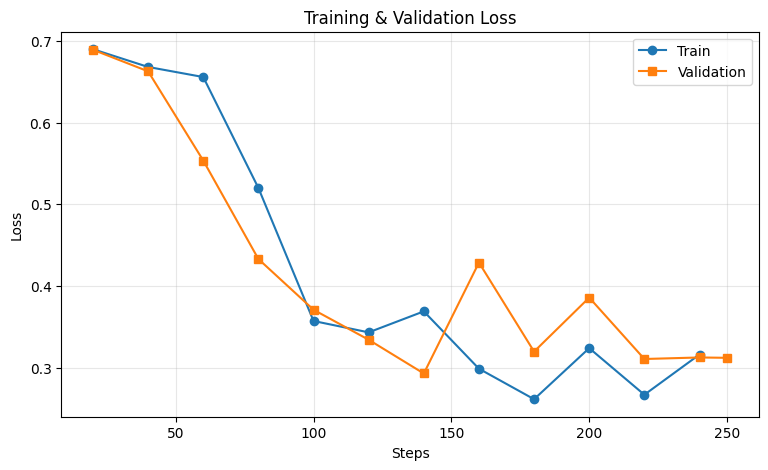

In [ ]:
import matplotlib.pyplot as plt

history = trainer.state.log_history
train = [x for x in history if "loss" in x]
val = [x for x in history if "eval_loss" in x]

print(f"Train: {len(train)} điểm | Validation: {len(val)} điểm")

plt.figure(figsize=(9, 5))
plt.plot([x["step"] for x in train], [x["loss"] for x in train], "o-", label="Train")
plt.plot([x["step"] for x in val], [x["eval_loss"] for x in val], "s-", label="Validation")
plt.xlabel("Steps")
plt.ylabel("Loss")
plt.title("Training & Validation Loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [ ]:
# Step 7: Evaluate the fine-tuned model
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)

    acc = accuracy_score(labels, preds)
    precision, recall, f1, _ = precision_recall_fscore_support(labels, preds, average='binary')

    return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}

trainer.compute_metrics = compute_metrics
eval_results = trainer.evaluate(eval_dataset=tokenized_test)

Training Loss,Validation Loss,Step,Accuracy,Precision,Recall,F1
0.315978,0.363583,250,0.830000,0.792453,0.875000,0.831683


In [ ]:
import torch
import numpy as np
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, DataCollatorWithPadding, TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Tải và chuẩn bị dữ liệu
dataset = load_dataset("stanfordnlp/imdb")
shuffled_train = dataset["train"].shuffle(seed=42)
train_dataset = shuffled_train.select(range(1000))
val_dataset = shuffled_train.select(range(1000, 1200))
test_dataset = dataset["test"].shuffle(seed=42).select(range(200))

# 2. Tải mô hình và Tokenizer
model_name = "distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=2,
    id2label={0: "NEGATIVE", 1: "POSITIVE"},
    label2id={"NEGATIVE": 0, "POSITIVE": 1}
)

# 3. Tokenize dữ liệu
def tokenize_function(examples):
    return tokenizer(examples["text"], truncation=True, max_length=256)

tokenized_train = train_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_val = val_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
tokenized_test = test_dataset.map(tokenize_function, batched=True, remove_columns=["text"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

# 4. Cấu hình huấn luyện
training_args = TrainingArguments(
    output_dir="./exercise2_results",
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="steps",
    save_steps=20,
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    num_train_epochs=2,
    weight_decay=0.01,
    max_grad_norm=1.0,
    logging_steps=20,
    report_to="none",
    fp16=torch.cuda.is_available()
)

# 5. Định nghĩa hàm tính metrics
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, preds, average="binary", zero_division=0
    )
    return {
        "accuracy": accuracy_score(labels, preds),
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# 6. Thiết lập Trainer và bắt đầu huấn luyện
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_val,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics
)

print("Đang bắt đầu huấn luyện mô hình (Fine-tuning)... ")
trainer.train()
print("Đã huấn luyện xong thành công!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Đang bắt đầu huấn luyện mô hình (Fine-tuning)... 


Step,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
20,0.689807,0.689119,0.465000,1.000000,0.018349,0.036036
40,0.668085,0.662727,0.515000,0.928571,0.119266,0.211382
60,0.655745,0.553474,0.760000,0.704698,0.963303,0.813953
80,0.519884,0.432877,0.830000,0.790698,0.935780,0.857143
100,0.357028,0.370772,0.840000,0.793893,0.954128,0.866667
120,0.343082,0.334035,0.880000,0.947368,0.825688,0.882353
140,0.368809,0.292736,0.895000,0.923077,0.880734,0.901408
160,0.298571,0.428559,0.835000,0.952381,0.733945,0.829016
180,0.261218,0.319526,0.890000,0.914286,0.880734,0.897196
200,0.323785,0.385663,0.860000,0.955056,0.779817,0.858586


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (8 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã huấn luyện xong thành công!
